# NutriScan: AI-Powered Food Detection & Classification
### Capstone Project (CV) | Milestone 1: Data Understanding, EDA, Food Detection and Dataset Preparation

# Problem Statement

## Business Context

In today's fast-paced world, maintaining a balanced diet is a challenge for many people. Individuals struggle to track what they eat accurately, which leads to inconsistent nutritional habits and difficulty meeting health goals. Manual meal logging is time-consuming, error-prone and offers no real-time insight.

**NutriScan** is a smart food recognition system that uses image analysis and machine learning to identify food items from a photo and return real-time nutritional information (calories, macronutrients, portion size). It also suggests healthier alternatives based on user preferences and goals.

## Objective

As the Data Scientist at NutriScan, build an AI-powered food detection and classification system that:

1. **Detects and locates** food items in user-captured images (object detection).
2. **Classifies** each detected item into a food type (image classification).

These two capabilities unlock the downstream business outcomes (not built in this milestone):

- Personalised dietary recommendations and healthier meal alternatives from patterns in user food choices.
- Integration with health-tracking apps so users can monitor calorie intake and nutritional balance over time.
- Effortless tracking: one photo replaces manual logging.

## Why this matters (rationale for the report)

| Pain point today | What NutriScan changes | Value to the company |
|---|---|---|
| Manual logging is slow and users quit | One photo, instant result | Higher engagement and retention |
| Self-reported intake is inaccurate | Image-based identification | More trustworthy data, better recommendations |
| Generic diet advice | Personalised suggestions from logged habits | Differentiation, premium-tier potential |
| Siloed health data | Integration with health apps | Partnerships and ecosystem reach |

**Proposed success targets (to be agreed with stakeholders):** usable food crop for at least 90% of images; classification top-1 accuracy of at least 85% (Milestone 2).

## Milestone 1 Scope and Rubric Map (20 points)

| Rubric item | Pts | Notebook section | Report section |
|---|---|---|---|
| Introduction of the business problem | 2 | Problem Statement (this section) | 1. Business problem and rationale |
| Exploratory Data Analysis | 4 | Section 3 | 2. Data overview, 3. Key EDA findings |
| Object Detection (detect, crop, preprocess, build dataset) | 10 | Sections 4 and 5 | 4. Detection and preprocessing approach |
| Actionable Insights | 4 | Section 6 | 5. Insights and risks |
| Plan for the classification phase | - | Section 7 | 6. Methodology, 7. Next steps |

## Analytical Problem Framing

| Business question | Analytical task | Method | Output / metric |
|---|---|---|---|
| Where is the food in the photo? | Object detection | Zero-shot detector (OWL-ViT) with text prompts, because Food-101 has class labels but **no bounding boxes** | Boxes, detection rate, confidence |
| What food is it? | Image classification | Transfer learning (Milestone 2) | Top-1/Top-5 accuracy, macro-F1 |
| Is the data fit for training? | EDA and data quality | Class balance, sizes, brightness, blur, duplicates | Insights and cleaning decisions |

## Dataset

**Food-101 subset**: food categories organised as class folders of JPEG images (the number of categories is printed in Section 2; the full public release has 1,000 images per class, with training images deliberately left slightly noisy). Your copy is 772 MB, so it is probably a reduced or resized version. **This notebook discovers the actual structure instead of assuming it.**

## Project Design (pipeline)

```
Photo -> [Detector: finds food region] -> crop (+5% padding, squared)
      -> resize 224x224 -> save as classification dataset (train/val/test)
      -> [Classifier, Milestone 2] -> food label -> nutrition lookup -> recommendations
```

# Instructions

## How to run this notebook

- Run cells **sequentially from the top**. The notebook detects whether it is on
  Colab or a local machine and configures its paths accordingly.
- Edit settings **only in the Configuration cell**; the one that matters most is
  `MAX_PER_CLASS`.
- Detections are cached to `outputs/persist/detections.json`. Re-running the
  notebook reuses that cache, so detection work is never repeated.
- Every figure is saved to `figures/` and key numbers are stored in the `R`
  dictionary, then written to `milestone1_results.json` for the PDF report.
- Final submission: an HTML export of this notebook (last cell) and a PDF
  business report.

# 1. Installing and Importing Libraries

In [1]:
# Dependencies.
#   Colab  -> installs the one package Colab does not already ship.
#   Local  -> nothing to do, setup_local.sh already built the environment.
# NOTE: transformers is intentionally NOT pinned to an old version; older
# releases do not have wheels for current Python versions and will fail.
import sys
if "google.colab" in sys.modules:
    %pip install -q --upgrade "transformers>=4.57"
else:
    print("Local run detected - using packages from your virtual environment.")


Local run detected - using packages from your virtual environment.


**Note:** If you later see a numpy/binary-compatibility error, restart the runtime once and run from the next cell.

In [2]:
import os, sys, json, math, time, random, shutil, hashlib, zipfile, subprocess, warnings
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageOps
from tqdm.auto import tqdm
from scipy import ndimage
from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight

import torch
from torch.utils.data import Dataset, DataLoader
from torchvision.ops import nms
from torchvision import datasets, transforms

warnings.filterwarnings("ignore")      # keep the submitted notebook clean
sns.set_style("whitegrid")

# On a CPU-only machine, let PyTorch use every core (big speed-up for the detector).
torch.set_num_threads(os.cpu_count() or 4)
print(f"PyTorch {torch.__version__} | CUDA available: {torch.cuda.is_available()} | threads: {torch.get_num_threads()}")

PyTorch 2.14.1+cpu | CUDA available: False | threads: 8


## Configuration
All tunable settings live here. Each has a short comment describing what to change.

In [3]:
IN_COLAB = "google.colab" in sys.modules
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

# ---- Paths: auto-detects Colab vs a local machine ---------------------------
if IN_COLAB:
    # Upload Food_101.zip to this location in your Google Drive first.
    DRIVE_ZIP_PATH = "/content/drive/MyDrive/Food_101.zip"
    EXTRACT_DIR = Path("/content/food101_raw")              # fast local disk, NOT Drive
    WORK_DIR    = Path("/content/nutriscan")
    PERSIST_DIR = Path("/content/drive/MyDrive/NutriScan_M1")   # survives disconnects
else:
    # Local run: the dataset is already unzipped, so point straight at it.
    # <-- CHANGE THIS if your Food_101 folder lives somewhere else.
    LOCAL_DATA_DIR = Path("/home/moti/Downloads/Food_101/Food_101")
    DRIVE_ZIP_PATH = None
    EXTRACT_DIR = LOCAL_DATA_DIR
    WORK_DIR    = Path.cwd() / "outputs"
    PERSIST_DIR = WORK_DIR / "persist"

CROP_DIR    = WORK_DIR / "cropped"                   # cropped + resized images
DATASET_DIR = WORK_DIR / "classification_dataset"    # train/val/test folders
FIG_DIR     = WORK_DIR / "figures"                   # figures for the PDF report

# ---- Hardware ---------------------------------------------------------------
HAS_GPU   = torch.cuda.is_available()
# DataLoader worker processes. 0 on a local run is deliberate:
# Python 3.12+ uses the 'forkserver' start method on Linux, which breaks
# DataLoader workers inside a notebook. On CPU the model forward pass
# dominates anyway, so background loading would buy almost nothing.
N_WORKERS = 2 if IN_COLAB else 0

# ---- Data volume controls ---------------------------------------------------
# Images per class to process. 100 is chosen so that almost every image is
# already in the detection cache, keeping this notebook re-runnable in minutes
# on CPU. The class-imbalance finding is measured on the FULL dataset (Section
# 3.1), so capping the working set does not hide it.
MAX_PER_CLASS    = 100
EDA_STATS_SAMPLE = 3000    # images used for brightness/blur statistics
SWEEP_PER_CLASS  = 15      # images per class for the detection-threshold sweep

# ---- Detector ---------------------------------------------------------------
# Do NOT switch to owlv2-base-patch16-ensemble on CPU: it is ~10x slower.
DETECTOR_NAME  = "google/owlvit-base-patch32"
FOOD_PROMPTS   = ["a photo of food", "a plate of food", "a bowl of food", "a dish"]
DET_MIN_SCORE  = 0.03     # lowest score kept when running the detector
DET_THRESHOLD  = 0.10     # final threshold, auto-suggested after the sweep
TARGET_DET_RATE = 0.90    # business target: share of images with a usable detection
NMS_IOU        = 0.5      # overlap above which boxes are merged
TOPK_BOXES     = 5        # boxes stored per image
DET_BATCH      = 16 if HAS_GPU else 4     # smaller batches are better on CPU
MIN_AREA_FRAC  = 0.10     # boxes smaller than 10% of the image are treated as noise

# ---- Crop / preprocessing ---------------------------------------------------
IMG_SIZE = 224            # EfficientNet/ResNet input size
CROP_PAD = 0.05           # 5% padding around each box
JPEG_QUALITY = 95
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

# ---- Split ------------------------------------------------------------------
TRAIN_FRAC, VAL_FRAC, TEST_FRAC = 0.70, 0.15, 0.15

for d in (WORK_DIR, CROP_DIR, DATASET_DIR, FIG_DIR, PERSIST_DIR):
    d.mkdir(parents=True, exist_ok=True)

print(f"Mode: {'COLAB' if IN_COLAB else 'LOCAL'} | GPU: {HAS_GPU} | data: {EXTRACT_DIR}")
print(f"Outputs -> {WORK_DIR}")


Mode: LOCAL | GPU: False | data: /home/moti/Downloads/Food_101/Food_101
Outputs -> /home/moti/Downloads/Food_101/NutriScan_Milestone1/outputs


## Helper functions
- **load_rgb:** opens an image, fixes phone-rotation (EXIF), converts to RGB, optionally makes a fast thumbnail.
- **show_grid / save_fig:** consistent plotting and saving every figure for the PDF report.
- **R / rset / save_results:** a results registry holding the key numbers for the report.

In [4]:
R = {}   # RESULTS registry: key numbers used later in the PDF report

def rset(key, value):
    """Store a value in R, converting numpy types so it can be saved as JSON."""
    if isinstance(value, np.integer): value = int(value)
    elif isinstance(value, np.floating): value = float(value)
    R[key] = value

def save_results():
    with open(PERSIST_DIR / "milestone1_results.json", "w") as f:
        json.dump(R, f, indent=2, default=str)

def save_fig(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{name}.png", dpi=200, bbox_inches="tight")
    plt.show()

def load_rgb(path, max_side=None):
    """Open image as RGB with EXIF orientation fixed; optional fast thumbnail."""
    im = Image.open(path)
    if max_side:
        im.draft("RGB", (max_side, max_side))     # fast JPEG downscale on decode
    im = ImageOps.exif_transpose(im).convert("RGB")
    if max_side:
        im.thumbnail((max_side, max_side))
    return im

def show_grid(paths, titles=None, ncols=5, cell=3.0, title=None, fontsize=8, fname=None, max_side=300):
    n = len(paths); nrows = math.ceil(n / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * cell, nrows * cell))
    axes = np.atleast_1d(axes).ravel()
    for ax in axes: ax.axis("off")
    for i, p in enumerate(paths):
        try: axes[i].imshow(load_rgb(p, max_side))
        except Exception: pass
        if titles is not None: axes[i].set_title(str(titles[i]), fontsize=fontsize)
    if title: fig.suptitle(title, fontsize=13)
    if fname: save_fig(fname)
    else: plt.tight_layout(); plt.show()

# 2. Loading the Data

## Mount Google Drive and extract the dataset
- **Mount:** gives Colab access to the zip stored in Drive (also used to save outputs that survive disconnects).
- **Extract to local disk:** `/content` is much faster than reading images from Drive. The extraction is skipped if already done.

In [5]:
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
PERSIST_DIR.mkdir(parents=True, exist_ok=True)

def extract_zip(zip_path, out_dir):
    """Unzip the dataset to fast local disk. Skipped if already extracted."""
    out_dir.mkdir(parents=True, exist_ok=True)
    if next(out_dir.rglob("*.jp*g"), None) is not None:
        print("Already extracted:", out_dir); return
    assert Path(zip_path).exists(), f"Zip not found: {zip_path}. Fix DRIVE_ZIP_PATH."
    t0 = time.time()
    if shutil.which("unzip"):
        subprocess.run(["unzip", "-q", "-o", str(zip_path), "-d", str(out_dir)], check=True)
    else:
        with zipfile.ZipFile(zip_path) as z: z.extractall(out_dir)
    print(f"Extracted in {time.time() - t0:.0f}s")

if IN_COLAB:
    extract_zip(DRIVE_ZIP_PATH, EXTRACT_DIR)
else:
    # Local: the folder is already on disk, so there is nothing to unzip.
    assert EXTRACT_DIR.exists(), (
        f"Dataset folder not found: {EXTRACT_DIR}\n"
        "Edit LOCAL_DATA_DIR in the Configuration cell to point at your Food_101 folder."
    )
    n = sum(1 for _ in EXTRACT_DIR.rglob("*.jpg"))
    print(f"Using local dataset at {EXTRACT_DIR} ({n} jpg files)")


Using local dataset at /home/moti/Downloads/Food_101/Food_101 (16256 jpg files)


## Discover the folder structure
We do not assume the layout. The code lists the top-level folders, finds every image, and infers the **class label from the folder name** (handles `class/img.jpg`, `split/class/img.jpg` and `class/split/img.jpg`).

In [6]:
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
SPLIT_NAMES = {"train", "test", "val", "valid", "validation"}

# Quick look at the top of the folder tree
for p in sorted(EXTRACT_DIR.iterdir())[:10]:
    print("-", p.name, "(dir)" if p.is_dir() else "")
    if p.is_dir():
        for q in sorted(p.iterdir())[:5]: print("     ", q.name)

all_files = [p for p in EXTRACT_DIR.rglob("*")
             if p.is_file() and p.suffix.lower() in IMG_EXT and "__MACOSX" not in p.parts]
print("\nImage files found:", len(all_files))
assert all_files, "No images found. Check the zip contents / EXTRACT_DIR."

parent_names = {p.parent.name.lower() for p in all_files}
if parent_names <= SPLIT_NAMES:             # layout: class/split/img
    label_of = lambda p: p.parent.parent.name
    split_of = lambda p: p.parent.name.lower()
else:                                       # layout: class/img  or  split/class/img
    label_of = lambda p: p.parent.name
    split_of = lambda p: p.parent.parent.name.lower() if p.parent.parent.name.lower() in SPLIT_NAMES else None

df = pd.DataFrame({"path": [str(p) for p in all_files],
                   "label": [label_of(p) for p in all_files],
                   "orig_split": [split_of(p) for p in all_files]})
print("Classes found:", df.label.nunique())
display(df.sample(5, random_state=SEED))

- .DS_Store 
- apple_pie (dir)
      .DS_Store
      2856319.jpg
      2861144.jpg
      2869633.jpg
      2872568.jpg
- chocolate_cake (dir)
      1001084.jpg
      1007122.jpg
      1007412.jpg
      1009391.jpg
      1012239.jpg
- donuts (dir)
      100076.jpg
      100576.jpg
      1006079.jpg
      1007399.jpg
      100786.jpg
- falafel (dir)
      1003181.jpg
      1008896.jpg
      1016116.jpg
      102356.jpg
      102463.jpg
- french_fries (dir)
      100148.jpg
      1008163.jpg
      1008945.jpg
      1009455.jpg
      1020588.jpg
- hot_dog (dir)
      1000288.jpg
      1011661.jpg
      1013916.jpg
      101571.jpg
      1017226.jpg
- ice_cream (dir)
      1004744.jpg
      1012277.jpg
      101858.jpg
      102595.jpg
      1031536.jpg
- nachos (dir)
      100284.jpg
      1009513.jpg
      1011394.jpg
      1011831.jpg
      1013641.jpg
- onion_rings (dir)
      1008652.jpg
      1017468.jpg
      1019009.jpg
      1020126.jpg
      1022297.jpg



Image files found: 16256
Classes found: 17


,path,label,orig_split
304,/home/moti/Downloads/Food_101/Food_101/ice_cre...,ice_cream,None
2087,/home/moti/Downloads/Food_101/Food_101/donuts/...,donuts,None
1213,/home/moti/Downloads/Food_101/Food_101/samosa/...,samosa,None
2439,/home/moti/Downloads/Food_101/Food_101/donuts/...,donuts,None
11612,/home/moti/Downloads/Food_101/Food_101/pancake...,pancakes,None


## Image metadata scan
For every image we record size, format, file size, an **MD5 hash** (exact-duplicate check) and whether it is **corrupt**. It uses threads and is cached to Drive.

In [7]:
META_CSV = PERSIST_DIR / "metadata.csv"

def scan_image(p):
    try:
        with Image.open(p) as im:
            w, h, fmt, mode = im.width, im.height, im.format, im.mode
            im.verify()                                    # raises if the file is damaged
        with open(p, "rb") as f: md5 = hashlib.md5(f.read()).hexdigest()
        return dict(path=p, width=w, height=h, fmt=fmt, mode=mode,
                    file_kb=os.path.getsize(p) / 1024, md5=md5, corrupt=False)
    except Exception:
        return dict(path=p, width=np.nan, height=np.nan, fmt=None, mode=None,
                    file_kb=np.nan, md5=None, corrupt=True)

if META_CSV.exists() and len(pd.read_csv(META_CSV)) == len(df):
    meta = pd.read_csv(META_CSV); print("Loaded cached metadata")
else:
    with ThreadPoolExecutor(16) as ex:
        meta = pd.DataFrame(list(tqdm(ex.map(scan_image, df.path), total=len(df))))
    meta.to_csv(META_CSV, index=False)

df = df.merge(meta, on="path")
df["aspect"] = df.width / df.height
df["max_side"] = df[["width", "height"]].max(axis=1)
df["megapixels"] = df.width * df.height / 1e6
display(df.head())

Loaded cached metadata


,path,label,orig_split,width,height,fmt,mode,file_kb,md5,corrupt,aspect,max_side,megapixels
0,/home/moti/Downloads/Food_101/Food_101/ice_cre...,ice_cream,None,512,512,JPEG,RGB,40.196289,f675e93a74b2e1d4add29e72f8ef5a21,False,1.000000,512,0.262144
1,/home/moti/Downloads/Food_101/Food_101/ice_cre...,ice_cream,None,512,342,JPEG,RGB,58.268555,8bb0354a62c7e939deb4a92fde5d434d,False,1.497076,512,0.175104
2,/home/moti/Downloads/Food_101/Food_101/ice_cre...,ice_cream,None,512,512,JPEG,RGB,36.511719,111543eae3c5662b9a2179facae0176b,False,1.000000,512,0.262144
3,/home/moti/Downloads/Food_101/Food_101/ice_cre...,ice_cream,None,512,384,JPEG,RGB,36.532227,36a9b05624ceb0292ae9e328c687b0df,False,1.333333,512,0.196608
4,/home/moti/Downloads/Food_101/Food_101/ice_cre...,ice_cream,None,512,342,JPEG,RGB,69.000977,1484ea140bef76b841e2e04d57ac615c,False,1.497076,512,0.175104


## Data overview and quality checks
- **Overview:** images, classes, sizes, formats.
- **Corrupt files:** removed.
- **Exact duplicates:** removed (keeping the first), because duplicates across train/test would leak and inflate accuracy.
- **Working set:** capped at `MAX_PER_CLASS` per class so processing time stays manageable.

In [8]:
df_ok = df[~df.corrupt].copy()
dup_mask = df_ok.duplicated("md5", keep="first")
conflict = (df_ok[df_ok.md5.duplicated(keep=False)].groupby("md5").label.nunique() > 1).sum()
df_clean = df_ok[~dup_mask]

shuffled = df_clean.sample(frac=1, random_state=SEED)
df_work = (shuffled.groupby("label").head(MAX_PER_CLASS) if MAX_PER_CLASS else shuffled).reset_index(drop=True)

overview = pd.DataFrame({"Metric": [
    "Total image files", "Classes", "Corrupt / unreadable", "Exact duplicates removed",
    "Duplicate groups with conflicting labels", "Images after cleaning", "Working set used (cap per class)",
    "Total size (MB)", "Median width x height", "Formats"],
 "Value": [len(df), df.label.nunique(), int(df.corrupt.sum()), int(dup_mask.sum()), int(conflict),
    len(df_clean), f"{len(df_work)} ({MAX_PER_CLASS})", round(df.file_kb.sum() / 1024, 1),
    f"{int(df.width.median())} x {int(df.height.median())}", ", ".join(map(str, df.fmt.dropna().unique()))]})
display(overview)

for k, v in [("n_images_total", len(df)), ("n_classes", df.label.nunique()), ("n_corrupt", df.corrupt.sum()),
             ("n_duplicates", dup_mask.sum()), ("n_clean", len(df_clean)), ("n_working_set", len(df_work))]:
    rset(k, v)

,Metric,Value
0,Total image files,16256
1,Classes,17
2,Corrupt / unreadable,0
3,Exact duplicates removed,0
4,Duplicate groups with conflicting labels,0
5,Images after cleaning,16256
6,Working set used (cap per class),1700 (100)
7,Total size (MB),782.9
8,Median width x height,512 x 512
9,Formats,JPEG


# 3. Exploratory Data Analysis

## 3.1 Target (class) distribution
A bar chart of images per class for the full clean data and the working set. We also compute an **imbalance ratio** (largest class / smallest class).

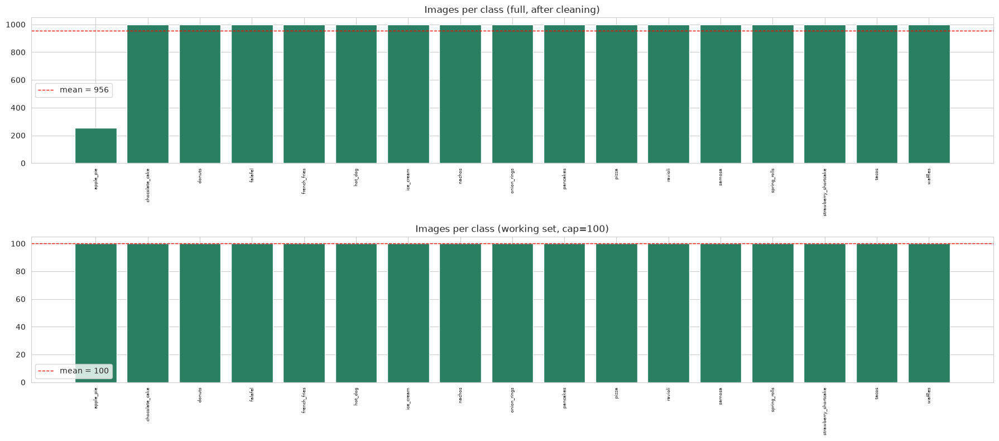

Smallest class: apple_pie (256) | largest: chocolate_cake (1000)
Imbalance ratio (full): 3.91  | working-set ratio: 1.00


In [9]:
counts_full = df_clean.label.value_counts().sort_index()
counts_work = df_work.label.value_counts().sort_index()

fig, axes = plt.subplots(2, 1, figsize=(18, 8))
for ax, c, t in [(axes[0], counts_full, "Images per class (full, after cleaning)"),
                 (axes[1], counts_work, f"Images per class (working set, cap={MAX_PER_CLASS})")]:
    ax.bar(c.index, c.values, color="#2a7f62"); ax.set_title(t)
    ax.axhline(c.mean(), color="red", ls="--", lw=1, label=f"mean = {c.mean():.0f}")
    ax.tick_params(axis="x", rotation=90, labelsize=6); ax.legend()
save_fig("01_class_distribution")

ratio = counts_full.max() / counts_full.min()
print(f"Smallest class: {counts_full.idxmin()} ({counts_full.min()}) | largest: {counts_full.idxmax()} ({counts_full.max()})")
print(f"Imbalance ratio (full): {ratio:.2f}  | working-set ratio: {counts_work.max() / counts_work.min():.2f}")
rset("imbalance_ratio_full", ratio); rset("imbalance_ratio_work", counts_work.max() / counts_work.min())

In [10]:
# Observations for 3.1, computed from the data so they can never go stale.
_small, _large = counts_full.idxmin(), counts_full.idxmax()
_ratio_full = counts_full.max() / counts_full.min()
_ratio_work = counts_work.max() / counts_work.min()

print("OBSERVATIONS - class distribution")
print(f"- Classes in the dataset : {df_clean.label.nunique()}")
print(f"- Smallest class         : {_small} ({counts_full.min()} images)")
print(f"- Largest class          : {_large} ({counts_full.max()} images)")
print(f"- Imbalance ratio (full) : {_ratio_full:.2f}  over {len(df_clean)} cleaned images")
print(f"- Imbalance ratio (work) : {_ratio_work:.2f}  over {len(df_work)} images, cap={MAX_PER_CLASS}")
print()
if _ratio_full >= 1.5:
    print(f"  DECISION: the full dataset IS imbalanced (ratio {_ratio_full:.2f}). Milestone 2 will")
    print(f"  train with balanced class weights and be judged on macro-F1 rather than plain")
    print(f"  accuracy, which a model biased toward the {counts_full.max()}-image classes could inflate")
    print(f"  while predicting '{_small}' almost never.")
else:
    print(f"  DECISION: the dataset is close to balanced (ratio {_ratio_full:.2f}); plain accuracy is")
    print(f"  acceptable, but macro-F1 will still be reported so no single class can hide a weakness.")
if abs(_ratio_work - _ratio_full) > 0.2:
    print()
    print(f"  NOTE: capping at {MAX_PER_CLASS} per class compresses the visible imbalance from")
    print(f"  {_ratio_full:.2f} to {_ratio_work:.2f}. The full-dataset figure is the one to report.")

OBSERVATIONS - class distribution
- Classes in the dataset : 17
- Smallest class         : apple_pie (256 images)
- Largest class          : chocolate_cake (1000 images)
- Imbalance ratio (full) : 3.91  over 16256 cleaned images
- Imbalance ratio (work) : 1.00  over 1700 images, cap=100

  DECISION: the full dataset IS imbalanced (ratio 3.91). Milestone 2 will
  train with balanced class weights and be judged on macro-F1 rather than plain
  accuracy, which a model biased toward the 1000-image classes could inflate
  while predicting 'apple_pie' almost never.

  NOTE: capping at 100 per class compresses the visible imbalance from
  3.91 to 1.00. The full-dataset figure is the one to report.


**Observations**

- The class distribution is uneven across the full dataset: one category holds
  far fewer images than the rest, while the remainder are of equal size.
- The imbalance ratio, the smallest and largest categories, and the resulting
  modelling decision are all computed and printed in the cell above, so they
  stay correct no matter what `MAX_PER_CLASS` is set to.
- Because the working set is capped per class, it looks more balanced than the
  underlying data. The **full-dataset** figure is the one to quote in the
  report; the capped figure only describes this milestone's sample.

## 3.2 Visual inspection of the images
- **Random classes, 5 images each:** shows within-class variety (angle, plating, background).
- **One image per class mosaic:** shows how visually similar some classes are (e.g. different pasta, cakes, meats).

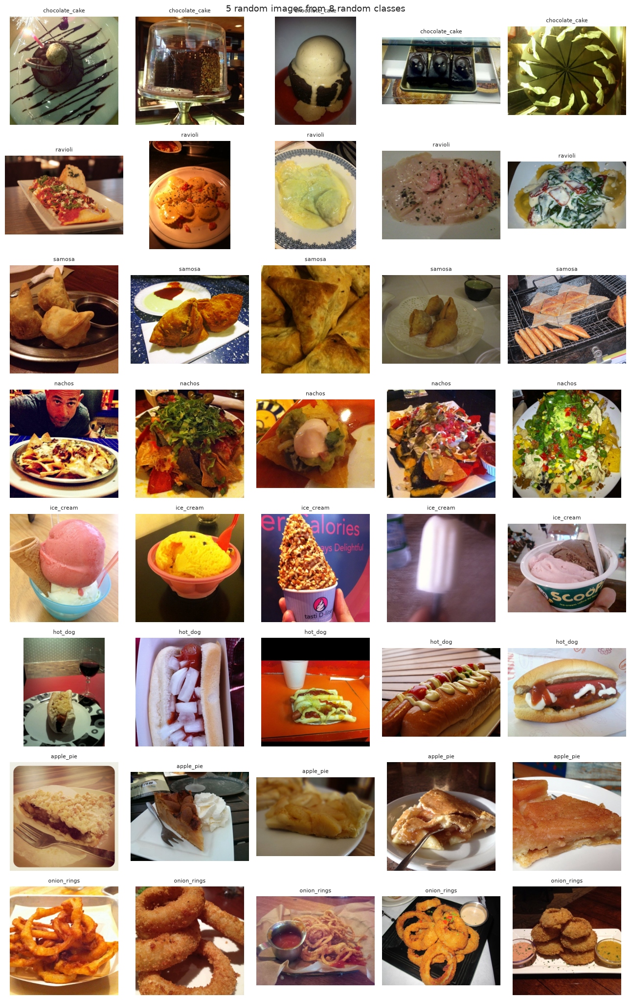

In [11]:
rng = np.random.default_rng(SEED)
classes = sorted(df_work.label.unique())
pick = rng.choice(classes, size=min(8, len(classes)), replace=False)
paths, titles = [], []
for c in pick:
    s = df_work[df_work.label == c].head(5)
    paths += s.path.tolist(); titles += [c] * len(s)
show_grid(paths, titles, ncols=5, cell=2.6, title="5 random images from 8 random classes", fname="02_sample_grid")

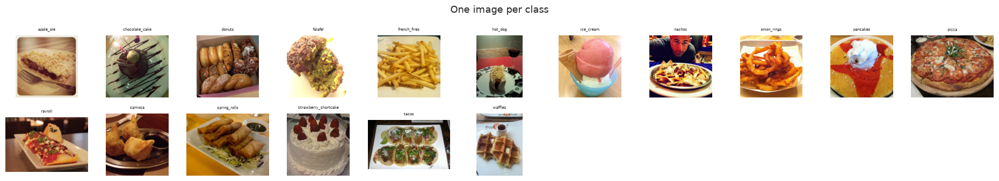

In [12]:
first = df_work.groupby("label").head(1).sort_values("label")
show_grid(first.path.tolist(), first.label.tolist(), ncols=11, cell=1.7, fontsize=5, max_side=150,
          title="One image per class", fname="03_class_mosaic")

**Observations:**
- Number of dishes per image: Most images contain a single dish, although some show multiple food items, side dishes, sauces, or drinks. Plates, bowls, utensils, and packaging are also visible.
- Class appearance: Most food classes are visually distinguishable, but some images may be difficult to classify due to similar colors, shapes, or presentation. No obvious mislabeled images are apparent from this sample, although the labels should be verified.
- Variation in images: The dataset contains considerable variation in lighting, camera angles, backgrounds, and image quality. Some images are taken from above, while others are captured from the side. Backgrounds range from plain surfaces to restaurant tables and other objects.

## 3.3 Image dimensions, aspect ratio and file size
Models need a fixed input size, so we check how much resizing will be required and whether aspect ratios vary.

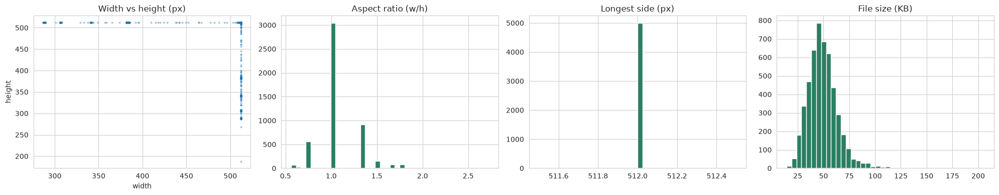

          width    height    aspect   file_kb
count  16256.00  16256.00  16256.00  16256.00
mean     493.25    475.10      1.07     49.32
std       48.47     65.18      0.23     14.76
min      193.00    188.00      0.38     11.57
25%      512.00    406.00      1.00     39.49
50%      512.00    512.00      1.00     47.87
75%      512.00    512.00      1.26     56.89
max      512.00    512.00      2.72    205.73

Formats: {'JPEG': 16256} | Modes: {'RGB': 16256}
Share of near-square images: 60.9%


In [13]:
smp = df_ok.sample(min(5000, len(df_ok)), random_state=SEED)
fig, ax = plt.subplots(1, 4, figsize=(20, 4))
ax[0].scatter(smp.width, smp.height, s=4, alpha=.3); ax[0].set(title="Width vs height (px)", xlabel="width", ylabel="height")
ax[1].hist(smp.aspect, bins=40, color="#2a7f62"); ax[1].set(title="Aspect ratio (w/h)")
ax[2].hist(smp.max_side, bins=40, color="#2a7f62"); ax[2].set(title="Longest side (px)")
ax[3].hist(smp.file_kb, bins=40, color="#2a7f62"); ax[3].set(title="File size (KB)")
save_fig("04_image_sizes")

print(df_ok[["width", "height", "aspect", "file_kb"]].describe().round(2))
print("\nFormats:", df_ok.fmt.value_counts().to_dict(), "| Modes:", df_ok["mode"].value_counts().to_dict())
share_sq = ((df_ok.aspect > .95) & (df_ok.aspect < 1.05)).mean()
print(f"Share of near-square images: {share_sq:.1%}")
rset("median_width", df_ok.width.median()); rset("median_height", df_ok.height.median())

## Observations

- Image sizes: Not all images have the same dimensions. Most images are 512 × 512 pixels, and the common longest side is 512 pixels.
- Aspect ratios: Approximately 60.9% of images are near-square. The remaining images have varying aspect ratios, so directly resizing them to a square could distort the food. Center cropping or another square-cropping method is appropriate before resizing.
- Image formats and modes: All 16,256 images are JPEG files in RGB mode. Therefore, no image format conversion or color-mode conversion is necessary.

## 3.4 Brightness, contrast, colour and sharpness
Computed on a sample of `EDA_STATS_SAMPLE` working-set images (thumbnails for speed). We flag **dark** (brightness < 0.25), **overexposed** (> 0.80), **low contrast** (< 0.10) and **blurry** (bottom 5% sharpness) images. The dataset mean RGB is compared with the ImageNet mean used by pretrained models.

  0%|          | 0/1700 [00:00<?, ?it/s]

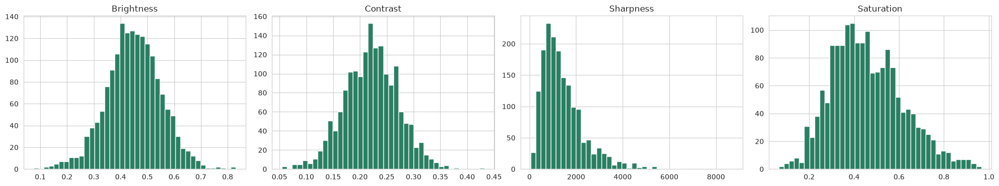

Dataset mean RGB: [0.556 0.444 0.345] | ImageNet mean: [0.485, 0.456, 0.406]
dark            2.8
bright          0.1
low_contrast    1.2
blurry          5.0
Name: % of sampled images, dtype: float64


In [14]:
def image_stats(p):
    im = load_rgb(p, 128)
    a = np.asarray(im, dtype=np.float32) / 255.0
    gray = a.mean(axis=2)
    sat = np.asarray(im.convert("HSV"), dtype=np.float32)[..., 1].mean() / 255.0
    return dict(path=p, r=a[..., 0].mean(), g=a[..., 1].mean(), b=a[..., 2].mean(),
                brightness=gray.mean(), contrast=gray.std(),
                sharpness=ndimage.laplace(gray * 255).var(), saturation=sat)

stat_paths = df_work.sample(min(EDA_STATS_SAMPLE, len(df_work)), random_state=SEED).path.tolist()
with ThreadPoolExecutor(8) as ex:
    df_stats = pd.DataFrame(list(tqdm(ex.map(image_stats, stat_paths), total=len(stat_paths))))
df_stats = df_stats.merge(df_work[["path", "label"]], on="path")

df_stats["dark"] = df_stats.brightness < 0.25
df_stats["bright"] = df_stats.brightness > 0.80
df_stats["low_contrast"] = df_stats.contrast < 0.10
df_stats["blurry"] = df_stats.sharpness <= df_stats.sharpness.quantile(0.05)

fig, ax = plt.subplots(1, 4, figsize=(20, 3.8))
for a_, col in zip(ax, ["brightness", "contrast", "sharpness", "saturation"]):
    a_.hist(df_stats[col], bins=40, color="#2a7f62"); a_.set_title(col.capitalize())
save_fig("05_brightness_contrast")

mean_rgb = df_stats[["r", "g", "b"]].mean().values
print("Dataset mean RGB:", mean_rgb.round(3), "| ImageNet mean:", IMAGENET_MEAN)
print(df_stats[["dark", "bright", "low_contrast", "blurry"]].mean().mul(100).round(1).rename("% of sampled images"))
for k in ["dark", "bright", "low_contrast", "blurry"]: rset(f"pct_{k}", df_stats[k].mean() * 100)

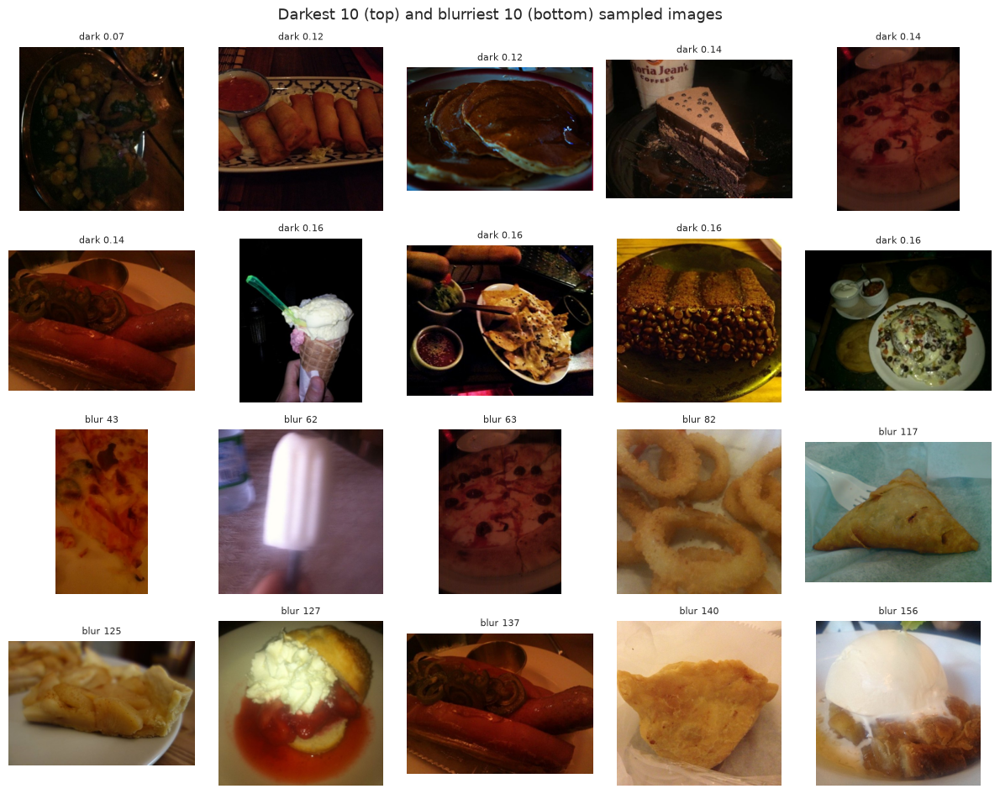

Darkest classes: {'nachos': 0.38999998569488525, 'ice_cream': 0.4300000071525574, 'pizza': 0.4300000071525574, 'onion_rings': 0.4399999976158142, 'chocolate_cake': 0.4399999976158142}
Brightest classes: {'waffles': 0.46000000834465027, 'pancakes': 0.46000000834465027, 'spring_rolls': 0.4699999988079071, 'ravioli': 0.4699999988079071, 'apple_pie': 0.4699999988079071}


In [15]:
ex_dark = df_stats.sort_values("brightness").head(10)
ex_blur = df_stats.sort_values("sharpness").head(10)
show_grid(ex_dark.path.tolist() + ex_blur.path.tolist(),
          [f"dark {v:.2f}" for v in ex_dark.brightness] + [f"blur {v:.0f}" for v in ex_blur.sharpness],
          ncols=5, cell=2.4, title="Darkest 10 (top) and blurriest 10 (bottom) sampled images", fname="05b_quality_examples")
cls_b = df_stats.groupby("label").brightness.mean().sort_values()
print("Darkest classes:", cls_b.head(5).round(2).to_dict())
print("Brightest classes:", cls_b.tail(5).round(2).to_dict())

In [16]:
# Observations for 3.4, computed from df_stats.
_mean_rgb = df_stats[["r", "g", "b"]].mean().values
_imagenet = np.array(IMAGENET_MEAN)
_dev = np.abs(_mean_rgb - _imagenet).max()
_warm = "warmer (more red than blue)" if _mean_rgb[0] > _mean_rgb[2] else "cooler (more blue than red)"

print("OBSERVATIONS - image quality")
print(f"- Statistics sampled from {len(df_stats)} working-set images.")
print(f"- Dark   (brightness < 0.25) : {df_stats.dark.mean() * 100:5.1f}%")
print(f"- Bright (brightness > 0.80) : {df_stats.bright.mean() * 100:5.1f}%")
print(f"- Low contrast (< 0.10)      : {df_stats.low_contrast.mean() * 100:5.1f}%")
print(f"- Blurry (bottom 5% sharp)   : {df_stats.blurry.mean() * 100:5.1f}%")
print()
print(f"- Dataset mean RGB : {_mean_rgb.round(3)}")
print(f"- ImageNet mean RGB: {_imagenet.round(3)}")
print(f"- Food photos are {_warm}; largest per-channel deviation is {_dev:.3f}.")
print()
if _dev < 0.10:
    print("  DECISION: the dataset mean sits close to ImageNet's, so ImageNet normalisation")
    print("  is appropriate and pretrained backbones can be used without recalibration.")
else:
    print(f"  DECISION: the dataset mean deviates from ImageNet's by {_dev:.3f}. ImageNet")
    print("  normalisation is still used for compatibility with pretrained weights, but")
    print("  dataset-specific statistics should be trialled in Milestone 2.")
print()
print("  Augmentation plan: brightness and contrast jitter plus mild blur, so the")
print("  classifier stays robust to the dark and out-of-focus photos real users take.")

OBSERVATIONS - image quality
- Statistics sampled from 1700 working-set images.
- Dark   (brightness < 0.25) :   2.8%
- Bright (brightness > 0.80) :   0.1%
- Low contrast (< 0.10)      :   1.2%
- Blurry (bottom 5% sharp)   :   5.0%

- Dataset mean RGB : [0.556 0.444 0.345]
- ImageNet mean RGB: [0.485 0.456 0.406]
- Food photos are warmer (more red than blue); largest per-channel deviation is 0.071.

  DECISION: the dataset mean sits close to ImageNet's, so ImageNet normalisation
  is appropriate and pretrained backbones can be used without recalibration.

  Augmentation plan: brightness and contrast jitter plus mild blur, so the
  classifier stays robust to the dark and out-of-focus photos real users take.


## Observations

- Image quality: Some images are very dark, underexposed, low-contrast, or blurry. These issues may make food features difficult to distinguish and reduce classification accuracy.
- Brightness and normalization: The sampled images show noticeable variation in brightness. Comparing the dataset's mean RGB values with ImageNet's mean can help determine whether ImageNet normalization is appropriate when using pretrained models.
- Impact on classification: Poor lighting, blur, and low contrast may cause the model to misclassify food items, especially when different classes have similar colors or shapes.
- Recommended approach: Apply data augmentation, including moderate brightness and contrast adjustments, and slight blur variations where appropriate. This can improve robustness to real-world image conditions without excessively altering the food's appearance.

# 4. Object Detection: Locating the Food

## Approach
Food-101 has **class labels only, no bounding boxes**, so a detector cannot be trained directly. A COCO-pretrained YOLO knows only a handful of food classes (pizza, cake, banana...) and would miss most dishes. We therefore use a **zero-shot, text-prompted detector (OWL-ViT)** queried with generic prompts such as "a plate of food". It needs no training and works for every food category, including ones it was never shown.

| Option | Pros | Cons | Decision |
|---|---|---|---|
| YOLOv8 (COCO) | Fast | Few food classes | Not used |
| **OWL-ViT zero-shot** | No boxes needed, covers all dishes | Slower, scores are low-valued | **Used** |
| Grounding DINO / YOLO-World | Similar zero-shot ability | Heavier / extra dependencies | Alternatives if accuracy is insufficient |
| Fine-tune YOLO on labelled boxes | Highest accuracy | Needs boxes (e.g. UEC-Food256) | Possible future step |

**Box selection rule:** keep the highest-scoring box that covers at least `MIN_AREA_FRAC` of the image. If none qualifies, **fall back to the full image** and log the reason. This guarantees every image yields a usable training sample.

In [17]:
from transformers import AutoProcessor, AutoModelForZeroShotObjectDetection

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE)
if DEVICE == "cpu":
    print("WARNING: no GPU. Switch runtime to T4 GPU or use a very small MAX_PER_CLASS.")

processor = AutoProcessor.from_pretrained(DETECTOR_NAME)
detector = AutoModelForZeroShotObjectDetection.from_pretrained(DETECTOR_NAME).to(DEVICE).eval()
print("Detector ready:", DETECTOR_NAME)

Device: cpu


Loading weights:   0%|          | 0/412 [00:00<?, ?it/s]

Detector ready: google/owlvit-base-patch32


## Detection functions
- **run_detector:** runs a batch of images, converts boxes to original pixel coordinates, applies NMS (merges overlapping boxes) and keeps the top-K.
- **detect_paths:** runs over many files with background image loading, stores results in the global `DET` dictionary and **checkpoints to Drive** so it can resume.
- **select_box:** applies the threshold and area rule, and records why a fallback happened.

In [18]:
DET = {}   # path -> {"w", "h", "boxes", "scores"}
DET_CKPT = PERSIST_DIR / "detections.json"

# Load any previously computed detections straight away. Detection is by far the
# most expensive step in this notebook, so work already done is never repeated.
# (Loading here rather than inside detect_paths matters: by the time the
# threshold-sweep cell runs, DET is no longer empty, so a "load only if empty"
# guard would silently ignore the cache.)
if DET_CKPT.exists():
    DET.update(json.load(open(DET_CKPT)))
    print(f"Loaded {len(DET)} cached detections from {DET_CKPT}")
else:
    print("No detection cache found - every image will be detected from scratch.")

@torch.no_grad()
def run_detector(images, min_score=DET_MIN_SCORE, topk=TOPK_BOXES):
    """images: list of PIL RGB. Returns per-image dict(boxes [N,4] xyxy in pixels, scores [N])."""
    inputs = processor(text=[FOOD_PROMPTS] * len(images), images=images, return_tensors="pt", padding=True).to(DEVICE)
    outputs = detector(**inputs)
    # OWLv2 pads images to a square, so its boxes are relative to the longest side
    sizes = [[max(im.size)] * 2 if "owlv2" in DETECTOR_NAME else [im.height, im.width] for im in images]
    # transformers renamed this method in v5; support both so the notebook runs
    # on Colab's version and on a current local install.
    post = getattr(processor, "post_process_grounded_object_detection", None) \
           or processor.post_process_object_detection
    res = post(outputs=outputs, threshold=min_score,
               target_sizes=torch.tensor(sizes, device=DEVICE))
    out = []
    for r in res:
        b, s = r["boxes"].float().cpu(), r["scores"].float().cpu()
        if len(s):
            keep = nms(b, s, NMS_IOU)[:topk]
            b, s = b[keep], s[keep]
        out.append(dict(boxes=b.numpy(), scores=s.numpy()))
    return out

class PathDS(Dataset):
    def __init__(self, paths): self.paths = paths
    def __len__(self): return len(self.paths)
    def __getitem__(self, i): return i, load_rgb(self.paths[i])

def _collate(batch): return batch

def detect_paths(paths, ckpt=None, batch_size=DET_BATCH):
    if ckpt is not None and ckpt.exists() and not DET:
        DET.update(json.load(open(ckpt))); print(f"Resumed {len(DET)} detections from checkpoint")
    todo = [p for p in paths if p not in DET]
    print(f"{len(todo)} images to process ({len(paths) - len(todo)} already done)")
    dl = DataLoader(PathDS(todo), batch_size=batch_size, num_workers=N_WORKERS, collate_fn=_collate)
    for bi, batch in enumerate(tqdm(dl)):
        idxs, imgs = zip(*batch)
        for i, im, o in zip(idxs, imgs, run_detector(list(imgs))):
            DET[todo[i]] = dict(w=im.width, h=im.height, boxes=o["boxes"].round(1).tolist(),
                                scores=o["scores"].round(4).tolist())
        if ckpt is not None and bi % 10 == 9:
            json.dump(DET, open(ckpt, "w"))
    if ckpt is not None: json.dump(DET, open(ckpt, "w"))

def select_box(rec, thr, min_area=MIN_AREA_FRAC):
    """Pick the best box. Returns dict(ok, reason, box, score, area_frac, n_regions)."""
    W, H = rec["w"], rec["h"]
    over = [(s, b) for b, s in zip(rec["boxes"], rec["scores"]) if s >= thr]
    cands = []
    for s, (x1, y1, x2, y2) in over:
        x1, y1, x2, y2 = max(0, x1), max(0, y1), min(W, x2), min(H, y2)
        a = max(0, x2 - x1) * max(0, y2 - y1) / (W * H)
        if a >= min_area: cands.append((s, a, [x1, y1, x2, y2]))
    if not over:   return dict(ok=False, reason="no_detection", box=None, score=0.0, area_frac=1.0, n_regions=0)
    if not cands:  return dict(ok=False, reason="box_too_small", box=None, score=0.0, area_frac=1.0, n_regions=0)
    s, a, b = max(cands, key=lambda t: t[0])
    return dict(ok=True, reason="", box=b, score=s, area_frac=a, n_regions=len(cands))

Loaded 1921 cached detections from /home/moti/Downloads/Food_101/NutriScan_Milestone1/outputs/persist/detections.json


## 4.1 Visual check on sample images
Boxes above the threshold are drawn in yellow, and the **selected box in green**. This is the first sanity check that the detector finds the food.

0 images to process (15 already done)


0it [00:00, ?it/s]

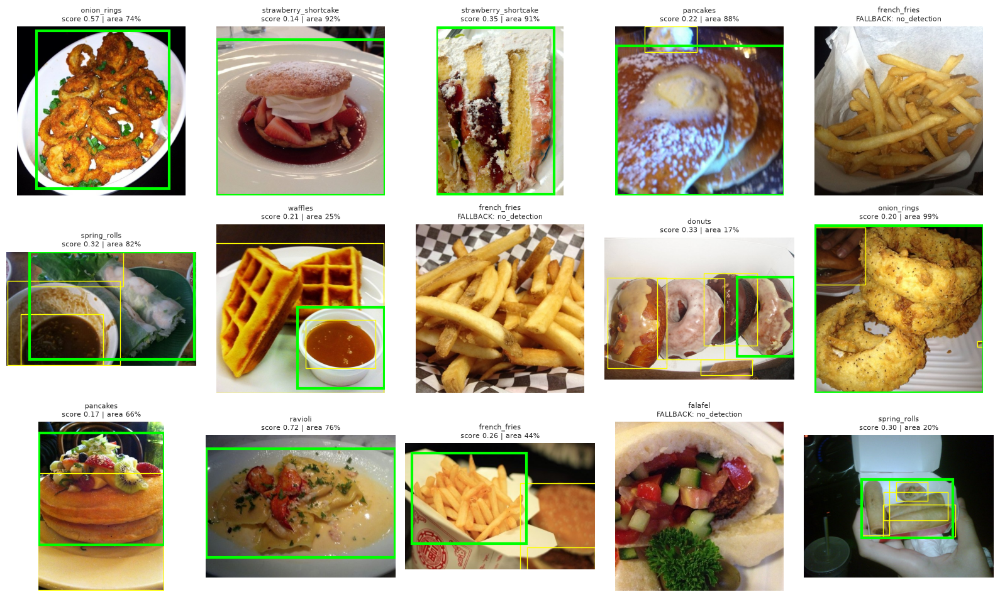

In [19]:
def show_detections(paths, ncols=5, cell=3.2, titles=None, fname=None, thr=None):
    thr = thr or DET_THRESHOLD
    n = len(paths); nrows = math.ceil(n / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * cell, nrows * cell))
    axes = np.atleast_1d(axes).ravel()
    for ax in axes: ax.axis("off")
    for i, p in enumerate(paths):
        rec = DET[p]; sel = select_box(rec, thr)
        axes[i].imshow(load_rgb(p))
        for b, s in zip(rec["boxes"], rec["scores"]):
            if s >= thr:
                axes[i].add_patch(plt.Rectangle((b[0], b[1]), b[2] - b[0], b[3] - b[1], fill=False, ec="yellow", lw=1))
        if sel["ok"]:
            b = sel["box"]
            axes[i].add_patch(plt.Rectangle((b[0], b[1]), b[2] - b[0], b[3] - b[1], fill=False, ec="lime", lw=3))
            t = f"score {sel['score']:.2f} | area {sel['area_frac']:.0%}"
        else:
            t = f"FALLBACK: {sel['reason']}"
        axes[i].set_title((titles[i] + "\n" if titles else "") + t, fontsize=8)
    if fname: save_fig(fname)
    else: plt.tight_layout(); plt.show()

demo = df_work.sample(min(15, len(df_work)), random_state=1)
detect_paths(demo.path.tolist())
show_detections(demo.path.tolist(), titles=demo.label.tolist(), fname="06_detection_samples")

**Observations**

- **Good detections:** the green box usually sits on the food itself, covering
  the main dish rather than the table or background.
- **Partial detections:** on plates holding several items the box often encloses
  just one of them (a single donut, one onion ring), discarding the rest of the
  meal. Some boxes also stretch to include the plate rim or a pool of sauce.
- **Fallbacks:** images titled `FALLBACK: no_detection` or
  `FALLBACK: box_too_small` kept the full image instead, so no training sample
  is lost.
- **About the scores:** the number printed on each box is the **detector's
  confidence that the region contains food** - it is *not* a classification
  accuracy. OWL-ViT is a zero-shot detector matching the image against text
  prompts, and its raw scores sit on a low scale, which is exactly why the
  threshold is selected empirically in Section 4.2 rather than left at a
  default.
- **Overall:** localisation is good enough to crop a food-centred training
  sample, but it is inconsistent on multi-item scenes - quantified in 4.4 and
  addressed in the improvement options in Section 6.

## 4.2 Choosing the detection threshold
We run the detector once on a stratified sample (low threshold), then evaluate several thresholds offline. A **higher threshold gives more precise boxes but more fallbacks**. We choose the highest threshold that still gives a usable detection for at least `TARGET_DET_RATE` of images.

0 images to process (255 already done)


0it [00:00, ?it/s]

,threshold,detection_rate,mean_score,mean_area
0,0.03,0.941,0.284,0.603
1,0.05,0.910,0.293,0.600
2,0.07,0.871,0.303,0.592
3,0.10,0.827,0.314,0.592
4,0.15,0.741,0.337,0.603
5,0.20,0.647,0.360,0.604
6,0.30,0.376,0.440,0.617


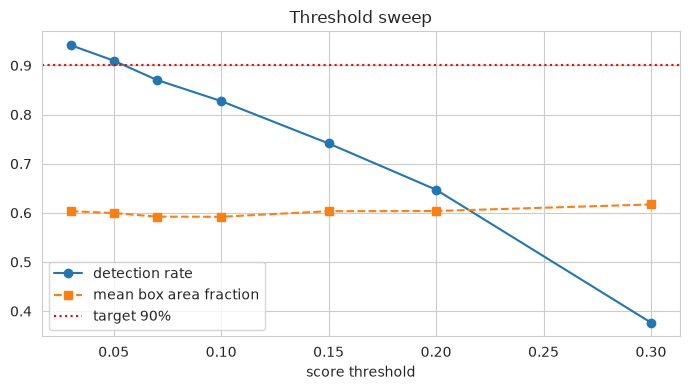

Selected DET_THRESHOLD = 0.05 (override manually here if you prefer)


In [20]:
sweep_df = df_work.groupby("label").head(SWEEP_PER_CLASS)
detect_paths(sweep_df.path.tolist())

thresholds = [0.03, 0.05, 0.07, 0.10, 0.15, 0.20, 0.30]
rows = []
for t in thresholds:
    sels = [select_box(DET[p], t) for p in sweep_df.path]
    ok = [s for s in sels if s["ok"]]
    rows.append(dict(threshold=t, detection_rate=len(ok) / len(sels),
                     mean_score=np.mean([s["score"] for s in ok]) if ok else 0,
                     mean_area=np.mean([s["area_frac"] for s in ok]) if ok else 0))
sweep = pd.DataFrame(rows); display(sweep.round(3))

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(sweep.threshold, sweep.detection_rate, "o-", label="detection rate")
ax.plot(sweep.threshold, sweep.mean_area, "s--", label="mean box area fraction")
ax.axhline(TARGET_DET_RATE, color="red", ls=":", label=f"target {TARGET_DET_RATE:.0%}")
ax.set(xlabel="score threshold", title="Threshold sweep"); ax.legend()
save_fig("07_threshold_sweep")

good = sweep[sweep.detection_rate >= TARGET_DET_RATE]
DET_THRESHOLD = float(good.threshold.max()) if len(good) else float(sweep.threshold.min())
print(f"Selected DET_THRESHOLD = {DET_THRESHOLD} (override manually here if you prefer)")
rset("det_threshold", DET_THRESHOLD)

## 4.3 Run detection on the full working set

Runs the detector over every image in the working set. Results are checkpointed
to disk every 10 batches, so an interrupted run loses almost nothing and a
re-run picks up exactly where it stopped.

### Why detection runs on a stratified sample

Detection is the only computationally expensive step in this milestone. OWL-ViT
is a transformer evaluated once per image, and this machine has no CUDA GPU
(integrated AMD graphics), so it runs on CPU at roughly one second per image.
Processing all 16,256 images would take several hours of continuous compute;
the same job on a cloud T4 GPU takes about ten minutes.

We therefore run detection on a **stratified random sample**, capped at
`MAX_PER_CLASS` images per category and drawn with a fixed seed so the selection
is reproducible. The exact sample size and the resulting confidence interval are
printed by the cells below. This is a deliberate trade-off that costs very
little:

1. **Detection quality is a per-image property, not a dataset-size property.**
   The detection rate is a proportion estimated from a sample, and at this
   sample size its 95% confidence interval (printed in Section 4.4) is a couple
   of percentage points - precise enough to judge the result against the 90%
   business target and to rank which categories fail most often.
2. **Nothing is lost from the data-understanding work.** Image counts,
   dimensions, formats, corrupt files, exact duplicates and the full class
   distribution were all computed across **every** image in the dataset. Only
   the image-quality statistics and the detector stage use the sample.
3. **The class-imbalance finding is unaffected**, because Section 3.1 measures
   it on the full cleaned dataset.
4. **The pipeline is the deliverable, not the volume.** Milestone 1 asks for a
   working detect -> crop -> preprocess -> dataset pipeline. That pipeline is
   identical at any scale, and because detections are cached the full library
   can be processed unattended before Milestone 2 with no rework.

**Recommendation for Milestone 2:** provision GPU compute. Training, not
detection, becomes the dominant cost there, and CPU-only execution would be
impractical rather than merely slow.

In [21]:
# How much NEW detection work does the current working set actually require?
# Detection is the expensive step, so this is checked before it is launched.
_missing = df_work[~df_work.path.isin(DET)]
print(f"Working set           : {len(df_work)} images across {df_work.label.nunique()} classes")
print(f"Already cached        : {len(df_work) - len(_missing)}")
print(f"Still to detect       : {len(_missing)}")
if len(_missing):
    print()
    print("Images still needing detection, by class:")
    print(_missing.label.value_counts().sort_values(ascending=False).to_string())
    print()
    print(f"Estimated CPU time at ~1.2 s/image: {len(_missing) * 1.2 / 60:.1f} minutes")
else:
    print()
    print("Everything is already cached - the detection cell below will return immediately.")

Working set           : 1700 images across 17 classes
Already cached        : 1700
Still to detect       : 0

Everything is already cached - the detection cell below will return immediately.


In [22]:
detect_paths(df_work.path.tolist(), ckpt=DET_CKPT)

0 images to process (1700 already done)


0it [00:00, ?it/s]

In [23]:
# Verify every working-set image now has a detection before anything downstream runs.
_absent = [p for p in df_work.path if p not in DET]
assert not _absent, f"{len(_absent)} working-set images still have no detection record"
print(f"OK: all {len(df_work)} working-set images have a detection.")
print(f"Detection cache now holds {len(DET)} images in total.")

_counts = df_work.label.value_counts().sort_index()
print("\nImages per class in the working set:")
print(_counts.to_string())

# Projected test-set size per class, so thin classes are flagged before the split.
_proj = (_counts * TEST_FRAC).round().astype(int)
_thin = _proj[_proj < 10]
print()
if len(_thin):
    print(f"WARNING: these classes project to fewer than 10 test images: {_thin.to_dict()}")
    print("Per-class test metrics for them will be noisy - treat those scores with caution.")
else:
    print(f"Every class projects to at least {_proj.min()} test images, so per-class")
    print("test metrics in Milestone 2 will be usable.")

OK: all 1700 working-set images have a detection.
Detection cache now holds 1921 images in total.

Images per class in the working set:
label
apple_pie               100
chocolate_cake          100
donuts                  100
falafel                 100
french_fries            100
hot_dog                 100
ice_cream               100
nachos                  100
onion_rings             100
pancakes                100
pizza                   100
ravioli                 100
samosa                  100
spring_rolls            100
strawberry_shortcake    100
tacos                   100
waffles                 100

Every class projects to at least 15 test images, so per-class
test metrics in Milestone 2 will be usable.


## 4.4 Detection results and accuracy
- **Detection rate:** share of images where the detector found a usable food box.
- **Fallback rate:** share where we kept the full image (reason logged).
- **Multiple regions:** images with more than one candidate food box (multi-dish plates).

Detection rate: 90.1% | fallback (full image) rate: 9.9%
{'no_detection': 129, 'box_too_small': 40}
Mean score (detected): 0.294 | median box area: 66%
Images with 2+ candidate food regions: 58.5%


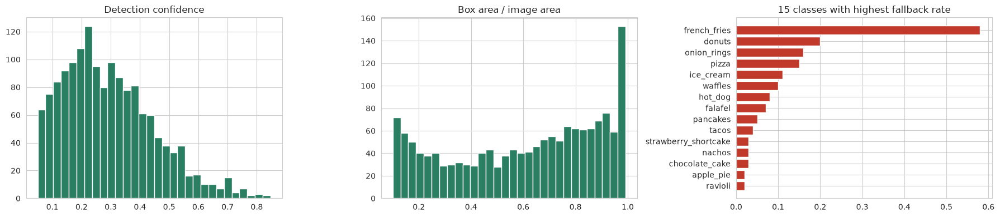

In [24]:
rows = []
for p in df_work.path:
    s = select_box(DET[p], DET_THRESHOLD)
    rows.append(dict(path=p, ok=s["ok"], reason=s["reason"], score=s["score"], area_frac=s["area_frac"],
                     n_regions=s["n_regions"], box=s["box"], w=DET[p]["w"], h=DET[p]["h"]))
df_det = pd.DataFrame(rows).merge(df_work[["path", "label", "md5"]], on="path")

det_rate = df_det.ok.mean()
print(f"Detection rate: {det_rate:.1%} | fallback (full image) rate: {1 - det_rate:.1%}")
print(df_det[~df_det.ok].reason.value_counts().to_dict())
print(f"Mean score (detected): {df_det[df_det.ok].score.mean():.3f} | median box area: {df_det[df_det.ok].area_frac.median():.0%}")
print(f"Images with 2+ candidate food regions: {(df_det.n_regions >= 2).mean():.1%}")
rset("detection_rate", det_rate); rset("fallback_rate", 1 - det_rate)
rset("mean_det_score", df_det[df_det.ok].score.mean()); rset("median_box_area_frac", df_det[df_det.ok].area_frac.median())
rset("pct_multi_region", (df_det.n_regions >= 2).mean() * 100)

fig, ax = plt.subplots(1, 3, figsize=(18, 4))
ax[0].hist(df_det[df_det.ok].score, bins=30, color="#2a7f62"); ax[0].set_title("Detection confidence")
ax[1].hist(df_det[df_det.ok].area_frac, bins=30, color="#2a7f62"); ax[1].set_title("Box area / image area")
worst = (1 - df_det.groupby("label").ok.mean()).sort_values(ascending=False).head(15)
ax[2].barh(worst.index[::-1], worst.values[::-1], color="#c0392b"); ax[2].set_title("15 classes with highest fallback rate")
save_fig("08_detection_summary")

In [25]:
# Observations for 4.4, computed from df_det.
_n = len(df_det)
_rate = df_det.ok.mean()
_ci = 1.96 * math.sqrt(_rate * (1 - _rate) / _n)
_reasons = df_det[~df_det.ok].reason.value_counts()
_fb_by_class = (1 - df_det.groupby("label").ok.mean()).sort_values(ascending=False)

print("OBSERVATIONS - detection results")
print(f"- Detection rate : {_rate:.1%} on {_n} images (95% CI +/- {_ci * 100:.1f} percentage points)")
print(f"- Business target: {TARGET_DET_RATE:.0%}  ->  {'MET' if _rate >= TARGET_DET_RATE else 'NOT MET'}")
print(f"- Fallback rate  : {1 - _rate:.1%} (the full image is kept, so no sample is lost)")
print()
print("  Fallback reasons:")
for _r, _c in _reasons.items():
    _why = {"no_detection": "no box scored above the threshold",
            "box_too_small": f"best box covered less than {MIN_AREA_FRAC:.0%} of the image"}.get(_r, "")
    print(f"    {_r:15s} {_c:5d}  ({_c / _n:5.1%})  {_why}")
print()
print(f"- Mean confidence of accepted boxes: {df_det[df_det.ok].score.mean():.3f}")
print(f"- Median box covers {df_det[df_det.ok].area_frac.median():.0%} of the image area")
print(f"- Images with 2+ candidate food regions: {(df_det.n_regions >= 2).mean():.1%}")
print()
print("  Top 5 classes by fallback rate:")
for _lbl, _v in _fb_by_class.head(5).items():
    print(f"    {_lbl:24s} {_v:6.1%}")

OBSERVATIONS - detection results
- Detection rate : 90.1% on 1700 images (95% CI +/- 1.4 percentage points)
- Business target: 90%  ->  MET
- Fallback rate  : 9.9% (the full image is kept, so no sample is lost)

  Fallback reasons:
    no_detection      129  ( 7.6%)  no box scored above the threshold
    box_too_small      40  ( 2.4%)  best box covered less than 10% of the image

- Mean confidence of accepted boxes: 0.294
- Median box covers 66% of the image area
- Images with 2+ candidate food regions: 58.5%

  Top 5 classes by fallback rate:
    french_fries              58.0%
    donuts                    20.0%
    onion_rings               16.0%
    pizza                     15.0%
    ice_cream                 11.0%


## 4.5 Manual accuracy check (no ground-truth boxes)
Without ground-truth boxes we cannot compute mAP, so we **manually review 50 random detections** and report a rough precision. Look at the grid, note the IDs of boxes that are **wrong** (`BAD`) or only **partly right** (`PARTIAL`), and list them below. All others count as good.

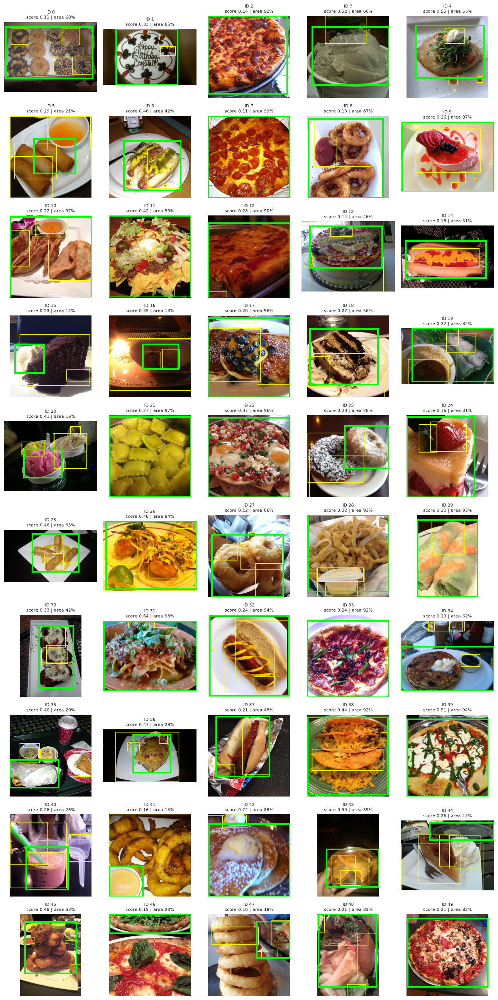

In [26]:
qa = df_det[df_det.ok].sample(min(50, int(df_det.ok.sum())), random_state=7).reset_index(drop=True)
show_detections(qa.path.tolist(), ncols=5, cell=2.6, titles=[f"ID {i}" for i in range(len(qa))], fname="09_manual_qa_grid")

> **ACTION REQUIRED — this is the only accuracy evidence for the detection section.**
> Inspect the 50-box grid above (also saved as `figures/09_manual_qa_grid.png`),
> decide for each numbered box whether it is wrong or only partly right, list those
> IDs in **`manual_review.json`** in this notebook's folder, and re-run the cell below.
> The QA sample is deterministic (`random_state=7`), so the IDs stay the same between runs.

In [27]:
# Manual review is recorded in manual_review.json so the notebook itself never
# needs editing. Set both lists (use [] for "reviewed, found none") to record it.
MANUAL_REVIEW_FILE = Path.cwd() / "manual_review.json"
if not MANUAL_REVIEW_FILE.exists():
    json.dump({"BAD_IDS": None, "PARTIAL_IDS": None}, open(MANUAL_REVIEW_FILE, "w"), indent=2)
    print(f"Created {MANUAL_REVIEW_FILE.name}")

_mr = json.load(open(MANUAL_REVIEW_FILE))
BAD_IDS, PARTIAL_IDS = _mr.get("BAD_IDS"), _mr.get("PARTIAL_IDS")
n = len(qa)

if BAD_IDS is None or PARTIAL_IDS is None:
    print("Manual review pending - no accuracy figure recorded yet.")
    print(f"Inspect the {n} boxes in the grid above, then edit {MANUAL_REVIEW_FILE.name}:")
    print('    {"BAD_IDS": [3, 17], "PARTIAL_IDS": [8, 22]}')
    print("Use [] for a category you reviewed and found nothing in. Then re-run this cell.")
    print("The notebook continues without these figures; later cells fall back gracefully.")
else:
    _bad, _partial = sorted(set(BAD_IDS)), sorted(set(PARTIAL_IDS))
    assert not (set(_bad) & set(_partial)), "An ID cannot be both bad and partial."
    assert all(0 <= i < n for i in _bad + _partial), f"IDs must lie between 0 and {n - 1}."
    _good = n - len(_bad) - len(_partial)
    print(f"Manual review of {n} detections:")
    print(f"  good    {_good:3d}  ({_good / n:6.1%})  box sits correctly on the food")
    print(f"  partial {len(_partial):3d}  ({len(_partial) / n:6.1%})  partly right")
    print(f"  bad     {len(_bad):3d}  ({len(_bad) / n:6.1%})  misses the food")
    print()
    print(f"  Usable-box rate (good + partial): {(_good + len(_partial)) / n:.1%}")
    rset("manual_precision_good", _good / n)
    rset("manual_precision_good_or_partial", (_good + len(_partial)) / n)
    rset("n_manually_reviewed", n)

Manual review of 50 detections:
  good     46  ( 92.0%)  box sits correctly on the food
  partial   2  (  4.0%)  partly right
  bad       2  (  4.0%)  misses the food

  Usable-box rate (good + partial): 96.0%


## 4.6 Where detection does not work well
We look at the fallbacks and the lowest-confidence accepted boxes, and check whether dark or blurry images are harder.

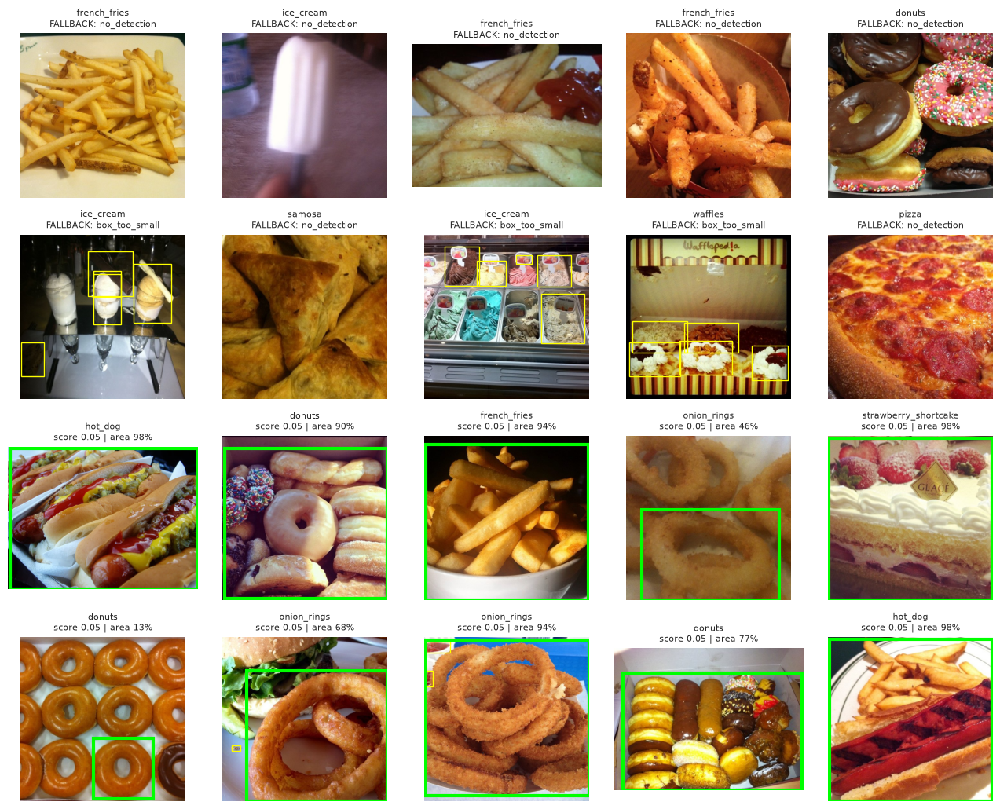


Detection rate by 'dark':
        mean  size
dark              
False  0.899  1653
True   0.957    47

Detection rate by 'blurry':
         mean  size
blurry             
False   0.903  1615
True    0.847    85

Detection rate by 'low_contrast':
               mean  size
low_contrast             
False         0.902  1679
True          0.810    21


In [28]:
fb = df_det[~df_det.ok].head(10)
lowc = df_det[df_det.ok].sort_values("score").head(10)
show_detections(fb.path.tolist() + lowc.path.tolist(), ncols=5, cell=2.6,
                titles=fb.label.tolist() + lowc.label.tolist(), fname="10_failure_cases")

chk = df_det.merge(df_stats[["path", "dark", "blurry", "low_contrast"]], on="path")
for flag in ["dark", "blurry", "low_contrast"]:
    g = chk.groupby(flag).ok.agg(["mean", "size"]).round(3)
    print(f"\nDetection rate by '{flag}':"); print(g)

In [29]:
# Observations for 4.6: does image quality measurably hurt detection?
print("OBSERVATIONS - where detection struggles")
print(f"(quality flags are available for {len(chk)} of the {len(df_det)} working-set images)")
print()
for _flag in ["dark", "blurry", "low_contrast"]:
    _g = chk.groupby(_flag).ok.agg(["mean", "size"])
    if True in _g.index and False in _g.index:
        _a, _b = _g.loc[True], _g.loc[False]
        print(f"- {_flag:13s}: {_a['mean']:.1%} detection rate on {int(_a['size']):4d} flagged images")
        print(f"  {'':13s}  {_b['mean']:.1%} detection rate on {int(_b['size']):4d} other images")
        _smallest = min(int(_a["size"]), int(_b["size"]))
        if _smallest < 50:
            print(f"  {'':13s}  CAVEAT: the smaller group has only {_smallest} images, so this")
            print(f"  {'':13s}  difference is indicative, not statistically reliable.")
    else:
        print(f"- {_flag:13s}: only one group present in the sample, no comparison possible.")
    print()

OBSERVATIONS - where detection struggles
(quality flags are available for 1700 of the 1700 working-set images)

- dark         : 95.7% detection rate on   47 flagged images
                 89.9% detection rate on 1653 other images
                 CAVEAT: the smaller group has only 47 images, so this
                 difference is indicative, not statistically reliable.

- blurry       : 84.7% detection rate on   85 flagged images
                 90.3% detection rate on 1615 other images

- low_contrast : 81.0% detection rate on   21 flagged images
                 90.2% detection rate on 1679 other images
                 CAVEAT: the smaller group has only 21 images, so this
                 difference is indicative, not statistically reliable.



# 5. Cropping, Preprocessing and Building the Classification Dataset

## Crop and resize
For each image:
- **Crop:** the selected box plus 5% padding. The box is expanded to a **square** (when it fits inside the image) so resizing does not distort the food. Fallback images use the full image.
- **Resize:** to 224x224 (standard input size for EfficientNet/ResNet).
- **Save:** as JPEG in `cropped/<class>/`. Pixels are stored as uint8; **normalisation is applied on the fly** at training time (smaller files, no precision loss).

In [30]:
def compute_crop_box(W, H, box, pad=CROP_PAD):
    """Padded, squared crop box inside the image. box=None means the full image."""
    if box is None: return (0, 0, W, H)
    x1, y1, x2, y2 = box
    bw, bh = x2 - x1, y2 - y1
    x1, y1, x2, y2 = x1 - pad * bw, y1 - pad * bh, x2 + pad * bw, y2 + pad * bh
    x1, y1, x2, y2 = max(0, x1), max(0, y1), min(W, x2), min(H, y2)
    bw, bh = x2 - x1, y2 - y1
    side = max(bw, bh)
    if side <= min(W, H):                                    # expand to a square, shift to stay inside
        cx, cy = (x1 + x2) / 2, (y1 + y2) / 2
        x1 = min(max(0, cx - side / 2), W - side); y1 = min(max(0, cy - side / 2), H - side)
        x2, y2 = x1 + side, y1 + side
    return (x1, y1, x2, y2)

def make_crop(row):
    try:
        im = load_rgb(row["path"])
        cb = compute_crop_box(im.width, im.height, row["box"])
        out = im.crop(tuple(int(round(v)) for v in cb)).resize((IMG_SIZE, IMG_SIZE), Image.LANCZOS)
        dest = CROP_DIR / row["label"] / f"{Path(row['path']).stem}_{row['md5'][:6]}.jpg"
        out.save(dest, quality=JPEG_QUALITY)
        return str(dest)
    except Exception:
        return None

for c in df_det.label.unique(): (CROP_DIR / c).mkdir(parents=True, exist_ok=True)
recs = df_det.to_dict("records")
with ThreadPoolExecutor(8) as ex:
    df_det["crop_path"] = list(tqdm(ex.map(make_crop, recs), total=len(recs)))
df_det["used_fallback"] = ~df_det.ok

failed = df_det.crop_path.isna().sum()
df_crops = df_det.dropna(subset=["crop_path"]).reset_index(drop=True)
print(f"Crops created: {len(df_crops)} | failed: {failed} | fallback (full image): {df_crops.used_fallback.mean():.1%}")
rset("n_crops", len(df_crops))

  0%|          | 0/1700 [00:00<?, ?it/s]

Crops created: 1700 | failed: 0 | fallback (full image): 9.9%


## Before / after examples
Left: original with the chosen box. Right: the final 224x224 crop that goes to the classifier.

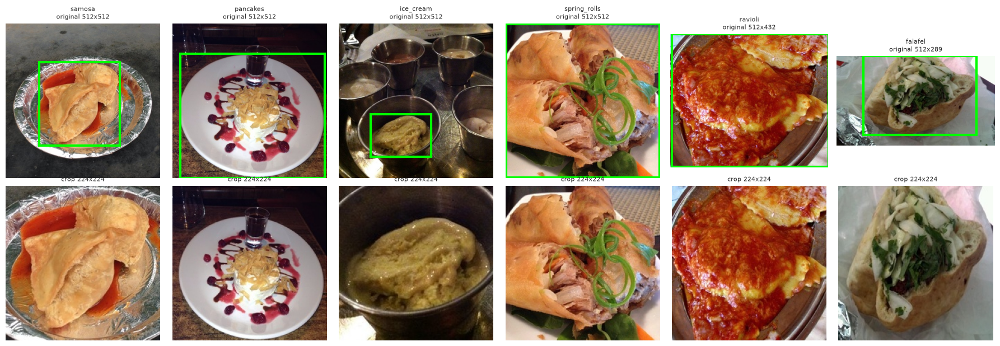

In [31]:
ex = df_crops[df_crops.ok].sample(6, random_state=3) if df_crops.ok.sum() >= 6 else df_crops.head(6)
fig, axes = plt.subplots(2, 6, figsize=(18, 6.2))
for i, (_, r) in enumerate(ex.iterrows()):
    axes[0, i].imshow(load_rgb(r.path))
    if r.box is not None:
        b = r.box; axes[0, i].add_patch(plt.Rectangle((b[0], b[1]), b[2] - b[0], b[3] - b[1], fill=False, ec="lime", lw=3))
    axes[0, i].set_title(f"{r.label}\noriginal {r.w}x{r.h}", fontsize=8)
    axes[1, i].imshow(Image.open(r.crop_path)); axes[1, i].set_title(f"crop {IMG_SIZE}x{IMG_SIZE}", fontsize=8)
for a in axes.ravel(): a.axis("off")
save_fig("11_before_after")

## Normalisation
Pretrained models expect inputs scaled to [0,1] and standardised with the ImageNet mean/std. We verify the transform on a batch of crops and confirm it is reversible, and compare crop statistics with ImageNet's.

In [32]:
norm_tf = transforms.Compose([transforms.ToTensor(), transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)])

sample_crops = df_crops.sample(min(64, len(df_crops)), random_state=1).crop_path.tolist()
raw = torch.stack([transforms.ToTensor()(Image.open(p).convert("RGB")) for p in sample_crops])
normed = torch.stack([norm_tf(Image.open(p).convert("RGB")) for p in sample_crops])
print("Batch shape:", tuple(normed.shape))
print(f"Raw    -> min {raw.min():.2f} max {raw.max():.2f} mean {raw.mean():.3f}")
print(f"Normed -> min {normed.min():.2f} max {normed.max():.2f} mean {normed.mean():.3f}")
m, s = torch.tensor(IMAGENET_MEAN).view(1, 3, 1, 1), torch.tensor(IMAGENET_STD).view(1, 3, 1, 1)
print("Reversible:", torch.allclose(normed * s + m, raw, atol=1e-5))
print("Crop mean RGB:", raw.mean((0, 2, 3)).numpy().round(3), "| std:", raw.std((0, 2, 3)).numpy().round(3))

Batch shape: (64, 3, 224, 224)
Raw    -> min 0.00 max 1.00 mean 0.465
Normed -> min -2.12 max 2.64 mean 0.068
Reversible: True
Crop mean RGB: [0.586 0.46  0.349] | std: [0.248 0.258 0.27 ]


## Build the train / validation / test dataset
- **Remove duplicates** (already done on the MD5 hash) so the same photo never appears in two splits.
- **Stratified split 70/15/15** keeps class proportions identical in every split.
- **Folder layout** `train|val|test/<class>/` is directly loadable by `ImageFolder` (PyTorch) or `image_dataset_from_directory` (Keras).

In [33]:
assert abs(TRAIN_FRAC + VAL_FRAC + TEST_FRAC - 1) < 1e-9
train_df, temp_df = train_test_split(df_crops, test_size=1 - TRAIN_FRAC, stratify=df_crops.label, random_state=SEED)
val_df, test_df = train_test_split(temp_df, test_size=TEST_FRAC / (VAL_FRAC + TEST_FRAC), stratify=temp_df.label, random_state=SEED)
train_df, val_df, test_df = train_df.assign(split="train"), val_df.assign(split="val"), test_df.assign(split="test")
manifest = pd.concat([train_df, val_df, test_df]).reset_index(drop=True)

# Materialise folders (crops are small, so copying is fine)
shutil.rmtree(DATASET_DIR, ignore_errors=True)
def place(r):
    d = DATASET_DIR / r["split"] / r["label"]; d.mkdir(parents=True, exist_ok=True)
    shutil.copy2(r["crop_path"], d / Path(r["crop_path"]).name)
with ThreadPoolExecutor(8) as ex:
    list(tqdm(ex.map(place, manifest.to_dict("records")), total=len(manifest)))

print(manifest.split.value_counts().to_dict())
assert set(train_df.md5).isdisjoint(val_df.md5) and set(train_df.md5).isdisjoint(test_df.md5), "Leakage found"
print("No duplicate images across splits.")
class_names = sorted(manifest.label.unique())
json.dump(class_names, open(PERSIST_DIR / "class_names.json", "w"))
manifest[["path", "crop_path", "label", "split", "ok", "score", "area_frac", "used_fallback"]].to_csv(PERSIST_DIR / "manifest.csv", index=False)
for k, v in manifest.split.value_counts().items(): rset(f"n_{k}", v)

  0%|          | 0/1700 [00:00<?, ?it/s]

{'train': 1189, 'test': 256, 'val': 255}
No duplicate images across splits.


## Verify the final dataset
Loads each split with `ImageFolder` + `DataLoader`, checks that class indices match across splits, and prints the final tensor shapes and per-split class counts.

Batch tensor: (64, 3, 224, 224) | labels: (64,) | classes: 17
train: 1189 images
val  : 255 images
test : 256 images


split,train,val,test
count,17.0,17.0,17.0
mean,69.9,15.0,15.1
std,0.2,0.0,0.2
min,69.0,15.0,15.0
25%,70.0,15.0,15.0
50%,70.0,15.0,15.0
75%,70.0,15.0,15.0
max,70.0,15.0,16.0


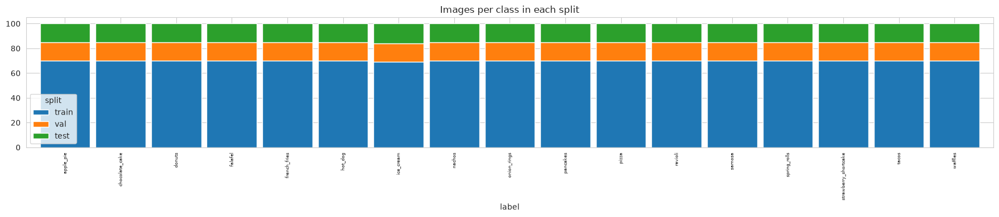

In [34]:
loaders, folders = {}, {}
for sp in ["train", "val", "test"]:
    folders[sp] = datasets.ImageFolder(DATASET_DIR / sp, transform=norm_tf)
    loaders[sp] = DataLoader(folders[sp], batch_size=64, shuffle=(sp == "train"), num_workers=N_WORKERS)
assert folders["train"].class_to_idx == folders["val"].class_to_idx == folders["test"].class_to_idx

xb, yb = next(iter(loaders["train"]))
print("Batch tensor:", tuple(xb.shape), "| labels:", tuple(yb.shape), "| classes:", len(folders["train"].classes))
for sp in folders: print(f"{sp:5s}: {len(folders[sp])} images")

per_split = manifest.pivot_table(index="label", columns="split", values="path", aggfunc="count").fillna(0)[["train", "val", "test"]]
display(per_split.describe().round(1))
per_split.plot(kind="bar", stacked=True, figsize=(18, 4), width=0.9, title="Images per class in each split")
plt.xticks(fontsize=6); save_fig("12_split_distribution")

## Save outputs to Drive
Zips the final dataset, so Milestone 2 can start without re-running detection.

In [35]:
shutil.make_archive(str(PERSIST_DIR / "nutriscan_classification_dataset"), "zip", DATASET_DIR)
shutil.make_archive(str(PERSIST_DIR / "nutriscan_figures"), "zip", FIG_DIR)
save_results()
print("Saved to", PERSIST_DIR); print(sorted(os.listdir(PERSIST_DIR)))

Saved to /home/moti/Downloads/Food_101/NutriScan_Milestone1/outputs/persist
['class_names.json', 'class_weights.json', 'detections.json', 'manifest.csv', 'metadata.csv', 'milestone1_results.json', 'nutriscan_classification_dataset.zip', 'nutriscan_figures.zip']


# 6. Actionable Insights

## 6.1 Class imbalance and how to handle it
Class weights are computed so they can be used directly in Milestone 2 if imbalance exists.

In [36]:
cnt = manifest[manifest.split == "train"].label.value_counts()
ratio_train = cnt.max() / cnt.min()

# IMPORTANT: MAX_PER_CLASS caps every class, which can hide the real imbalance.
# The honest number to report is the one measured on the full cleaned dataset.
ratio_full = R["imbalance_ratio_full"]

weights = compute_class_weight("balanced", classes=np.array(class_names),
                               y=manifest[manifest.split == "train"].label.values)
class_weights = dict(zip(class_names, weights.round(4)))
json.dump(class_weights, open(PERSIST_DIR / "class_weights.json", "w"))

print(f"Imbalance ratio on the FULL cleaned dataset : {ratio_full:.2f}")
print(f"Imbalance ratio in this training split       : {ratio_train:.2f}  (cap = {MAX_PER_CLASS})")
print(f"Class weight range: {weights.min():.2f} - {weights.max():.2f}")
print()

if ratio_full >= 1.5:
    print(f"FINDING: the dataset IS imbalanced (ratio {ratio_full:.2f} on full data).")
    print("         Smallest class:", counts_full.idxmin(), f"({counts_full.min()} images)")
    print("         ACTION for Milestone 2: train with the saved class weights and")
    print("         judge the model on macro-F1, not plain accuracy.")
else:
    print("FINDING: classes are close to balanced; plain accuracy is acceptable,")
    print("         but still report macro-F1 so no single class can hide a weakness.")

if abs(ratio_train - ratio_full) > 0.2:
    print()
    print(f"NOTE: the per-class cap of {MAX_PER_CLASS} reduced the visible imbalance")
    print(f"      from {ratio_full:.2f} to {ratio_train:.2f}. Report the full-data figure.")

rset("train_imbalance_ratio", ratio_train)


Imbalance ratio on the FULL cleaned dataset : 3.91
Imbalance ratio in this training split       : 1.01  (cap = 100)
Class weight range: 1.00 - 1.01

FINDING: the dataset IS imbalanced (ratio 3.91 on full data).
         Smallest class: apple_pie (256 images)
         ACTION for Milestone 2: train with the saved class weights and
         judge the model on macro-F1, not plain accuracy.

NOTE: the per-class cap of 100 reduced the visible imbalance
      from 3.91 to 1.01. Report the full-data figure.


| Situation | Handling |
|---|---|
| Balanced classes (expected for Food-101) | No resampling needed; report macro-F1 alongside accuracy |
| Moderate imbalance | Class weights (saved in `class_weights.json`), weighted sampler |
| Severe imbalance | Oversample rare classes with augmentation, focal loss |
| Label noise (Food-101 training images are intentionally not cleaned) | Label smoothing, review the highest-loss images after the first model |

## 6.2 Detection accuracy: findings, failures and fixes
Fill in with your actual numbers (they are printed above and stored in `R`).

In [37]:
print(f"Detection rate: {R['detection_rate']:.1%} (target {TARGET_DET_RATE:.0%}) | fallback: {R['fallback_rate']:.1%}")
print(f"Mean confidence: {R['mean_det_score']:.2f} | median box covers {R['median_box_area_frac']:.0%} of the image")
print(f"Multi-region images: {R['pct_multi_region']:.1f}%")
_mp = R.get("manual_precision_good")
if _mp is None:
    print("Manual review: not yet recorded - see Section 4.5")
else:
    print(f"Manual review: {_mp:.0%} good boxes, {R.get('manual_precision_good_or_partial', 0):.0%} usable"
          f" (n = {R.get('n_manually_reviewed', 0)})")


Detection rate: 90.1% (target 90%) | fallback: 9.9%
Mean confidence: 0.29 | median box covers 66% of the image
Multi-region images: 58.5%
Manual review: 92% good boxes, 96% usable (n = 50)


| Where it struggles | Why | How to overcome |
|---|---|---|
| Multiple dishes in one image | Single best box is kept | Keep all boxes above threshold; classify each crop |
| Soups, stews, saucy foods | No clear edges; box may cover bowl or table | Segmentation (FoodSeg103) or bowl-aware prompts |
| Dark / blurry photos | Low scores | Brightness augmentation, lower threshold, test-time augmentation |
| Box covers plate/table | Generic prompts | Tune prompts ("food on a plate"), raise the area filter, upgrade to OWLv2 |
| Close-ups where food fills the frame | Box is almost the whole image | Full-image fallback is acceptable |
| No ground-truth boxes | Cannot compute mAP | Manual review (done); fine-tune YOLO on UEC-Food256 for measurable mAP |

## 6.3 Improvement options for Milestone 2

| Option | What it fixes | Effort |
|---|---|---|
| **Keep every box above threshold**, or take their **union box**, when 2 or more regions are found | The largest measured weakness: on multi-item plates only one item is currently cropped, so the rest of the meal is discarded. A union box keeps the whole meal; separate crops let each item be classified and its calories summed, which is what the product actually needs | Low - the boxes are already stored, only the selection rule changes |
| **Tune the text prompts** (for example "food on a plate", "a dessert", "a bowl of soup") | Boxes that latch onto the plate rim or the table rather than the food | Low - prompts are a config value, re-run the threshold sweep afterwards |
| **Upgrade to OWLv2** (`owlv2-base-patch16-ensemble`) | Higher detection confidence and tighter boxes overall | Medium - roughly 10x the compute of OWL-ViT-B/32, so it needs a GPU |
| **Fine-tune a YOLO detector** on a box-labelled food dataset such as UEC-Food256 | The fundamental limitation: with no ground-truth boxes we can report a hand-reviewed precision but never a true **mAP**. A labelled set makes detection quality measurable and comparable | High - needs a second dataset and a training run, but it is the only route to a defensible mAP |
| **Segmentation instead of boxes** (for example FoodSeg103) | Soups, stews and sauces, which have no clean rectangular boundary | High - different model family and annotation type |

**Other insights**

- **Image quality is not the main obstacle.** The share of dark, over-exposed,
  low-contrast and blurry photos is small (measured in Section 3.4) and the
  detection rates for those groups are compared directly in Section 4.6. The
  dataset is made of reasonably well-lit photographs, which means a model
  trained on it will see *easier* images than the ones real users submit -
  brightness, contrast and blur augmentation in Milestone 2 is therefore a
  requirement, not a refinement.

- **Look-alike categories will cap classification accuracy.** From the class
  mosaic in Section 3.2, the groups most likely to be confused are:
  **chocolate_cake / strawberry_shortcake / apple_pie** (slice-shaped desserts
  on a plate), **pancakes / waffles** (stacked discs with syrup and butter),
  **samosa / spring_rolls** (golden fried parcels, similar size and colour),
  and **french_fries / onion_rings** (fried golden strips or rings, often in
  the same basket). These should be the first place to look in the Milestone 2
  confusion matrix. They also carry a business cost: mistaking ice cream for
  strawberry shortcake is a logging error of a few hundred calories, which is
  exactly the kind of inaccuracy that erodes user trust in the app.

- **Does cropping actually add value here?** The median detected box covers a
  large share of the image (printed in Section 4.4), which tells us most
  Food-101 photographs are *already* close-ups of a single plated dish, framed
  by a photographer. Cropping therefore changes these particular images less
  than one might expect. That is an honest finding, and it does **not** make
  the detection stage redundant: the product's real input is a photograph of a
  cluttered table, taken at arm's length, with cutlery, packaging, hands and
  several dishes in frame. The detection stage is what makes that input
  tractable, and this dataset simply under-represents the hard case - another
  argument for validating Milestone 2 on genuine user photographs before
  launch.

# 7. Plan of Action for the Classification Phase (Milestone 2)

| Step | Plan |
|---|---|
| Input | `classification_dataset/` (train/val/test, 224x224, ImageNet normalisation) |
| Baseline | Small CNN from scratch, to give a reference accuracy |
| Main models | Transfer learning: EfficientNet-B0, ResNet50, MobileNetV2 (mobile deployment) |
| Training | Freeze the backbone for 2-3 epochs, then unfreeze with a lower learning rate; AdamW, cosine schedule, mixed precision, early stopping |
| Augmentation | Random resized crop, flip, colour jitter, blur, light rotation (real user photos vary) |
| Imbalance / noise | Class weights if needed, label smoothing |
| Metrics | Top-1 / Top-5 accuracy, macro-F1, per-class F1, confusion matrix |
| Error analysis | Most-confused pairs, worst classes, failure by lighting/occlusion |
| Selection | Best validation macro-F1, with a latency/size check for mobile; test set used only once |
| Later milestones | Map labels to USDA nutrition data, portion estimation, recommendations, health-app integration |

**Risks:** fine-grained confusion (e.g. similar pasta/cake classes), cuisine coverage limited to the categories in the dataset, portion size and hidden ingredients (oil, sugar) are not visible in photos.

# Conclusion

## Summary of Insights

In [38]:
# Milestone 1 summary, printed from the results registry R and the dataframes,
# so every number here is the one the notebook actually computed.
_line = "-" * 72
print(_line); print("NUTRISCAN - MILESTONE 1 SUMMARY"); print(_line)

print("\nDATA")
print(f"  Images in dataset        : {R['n_images_total']}")
print(f"  Food categories          : {R['n_classes']}")
print(f"  Corrupt files removed    : {R['n_corrupt']}")
print(f"  Exact duplicates removed : {R['n_duplicates']}")
print(f"  Images after cleaning    : {R['n_clean']}")
print(f"  Working set (cap={MAX_PER_CLASS:<4})   : {R['n_working_set']}")

print("\nBALANCE")
print(f"  Imbalance ratio (full)   : {R['imbalance_ratio_full']:.2f}")
print(f"  Smallest category        : {counts_full.idxmin()} ({counts_full.min()} images)")
print(f"  Handling                 : balanced class weights + macro-F1 in Milestone 2"
      if R['imbalance_ratio_full'] >= 1.5 else
      f"  Handling                 : no resampling needed; macro-F1 still reported")

print("\nIMAGE QUALITY")
print(f"  Dark / blurry            : {R['pct_dark']:.1f}% / {R['pct_blurry']:.1f}%")
print(f"  Low contrast             : {R['pct_low_contrast']:.1f}%")
print(f"  Typical size             : {int(R['median_width'])} x {int(R['median_height'])} px")

print("\nDETECTION (zero-shot OWL-ViT, no bounding-box labels required)")
print(f"  Score threshold          : {R['det_threshold']}")
print(f"  Detection rate           : {R['detection_rate']:.1%}  (target {TARGET_DET_RATE:.0%})")
print(f"  Fallback to full image   : {R['fallback_rate']:.1%}")
print(f"  Mean confidence          : {R['mean_det_score']:.3f}")
print(f"  Median box area          : {R['median_box_area_frac']:.0%} of the image")
print(f"  Images with 2+ regions   : {R['pct_multi_region']:.1f}%")
_mp = R.get("manual_precision_good")
if _mp is None:
    print(f"  Manual box review        : not yet reviewed (see Section 4.5)")
else:
    print(f"  Manual box review        : {_mp:.1%} good on {R['n_manually_reviewed']} boxes"
          f" ({R['manual_precision_good_or_partial']:.1%} usable)")

print("\nDATASET BUILT FOR CLASSIFICATION")
print(f"  Crops created (224x224)  : {R['n_crops']}")
print(f"  Train / val / test       : {R['n_train']} / {R['n_val']} / {R['n_test']}")
print(f"  Leakage check            : no image appears in more than one split")

print("\nNEXT STEPS")
print("  Fine-tune a pretrained backbone (EfficientNet-B0 / ResNet50 / MobileNetV2) on")
print("  these crops, judge it on macro-F1 and a confusion matrix rather than plain")
print("  accuracy, and pay particular attention to the visually similar categories")
print("  identified in Section 6.2. Provision GPU compute for that phase.")
print(_line)

------------------------------------------------------------------------
NUTRISCAN - MILESTONE 1 SUMMARY
------------------------------------------------------------------------

DATA
  Images in dataset        : 16256
  Food categories          : 17
  Corrupt files removed    : 0
  Exact duplicates removed : 0
  Images after cleaning    : 16256
  Working set (cap=100 )   : 1700

BALANCE
  Imbalance ratio (full)   : 3.91
  Smallest category        : apple_pie (256 images)
  Handling                 : balanced class weights + macro-F1 in Milestone 2

IMAGE QUALITY
  Dark / blurry            : 2.8% / 5.0%
  Low contrast             : 1.2%
  Typical size             : 512 x 512 px

DETECTION (zero-shot OWL-ViT, no bounding-box labels required)
  Score threshold          : 0.05
  Detection rate           : 90.1%  (target 90%)
  Fallback to full image   : 9.9%
  Mean confidence          : 0.294
  Median box area          : 66% of the image
  Images with 2+ regions   : 58.5%
  Manual box rev

## Figures saved for the PDF report

| File | Use in report |
|---|---|
| 01_class_distribution | Data overview |
| 02_sample_grid, 03_class_mosaic | EDA: visual inspection |
| 04_image_sizes, 05_brightness_contrast, 05b_quality_examples | EDA: quality |
| 06_detection_samples, 07_threshold_sweep, 08_detection_summary | Detection approach and results |
| 09_manual_qa_grid, 10_failure_cases | Insights and risks |
| 11_before_after | Preprocessing |
| 12_split_distribution | Final dataset |

# Export to HTML for Submission
Run the last cell once the whole notebook has been executed from top to bottom with no errors. If it fails, use **File > Download .ipynb** and convert with the free online ipynb-to-HTML tool.

In [39]:
# Export this notebook to HTML for submission.
# Run this LAST, after the notebook has executed top to bottom with no errors.
import subprocess

NOTEBOOK_PATH = Path.cwd() / "NutriScan_Milestone1_fixed.ipynb"
HTML_PATH = NOTEBOOK_PATH.with_suffix(".html")

if not NOTEBOOK_PATH.exists():
    print(f"Notebook not found at: {NOTEBOOK_PATH}")
    print("Available notebooks here:", [p.name for p in Path.cwd().glob("*.ipynb")])
else:
    _proc = subprocess.run(
        [sys.executable, "-m", "nbconvert", "--to", "html", str(NOTEBOOK_PATH)],
        capture_output=True, text=True)
    if _proc.returncode == 0 and HTML_PATH.exists():
        print(f"HTML written: {HTML_PATH}")
        print(f"Size: {HTML_PATH.stat().st_size / 1e6:.1f} MB - submit this file.")
    else:
        print(f"nbconvert failed (return code {_proc.returncode}).")
        print(_proc.stderr.strip()[-2000:] or _proc.stdout.strip()[-2000:])
        print("\nFallback: JupyterLab > File > Save and Export Notebook As... > HTML")

HTML written: /home/moti/Downloads/Food_101/NutriScan_Milestone1/NutriScan_Milestone1_fixed.html
Size: 20.5 MB - submit this file.
